# 02 — Logistic regression by maximum likelihood: is this vendor a pharmacy?

**Phase 1, Step 4.** Target: `is_pharmacy` = 1 if the vendor appears in `pharmacy.json`.
These are **weak labels**: they record which Google Maps search returned the place, not a
verified fact. Some "pharmacies" are tuition centres or supermarkets, so every metric
below measures agreement with noisy labels.

All numbers in this notebook are computed by the code cells below
(`src/logistic_regression_classification.py`).

In [1]:
import os, sys, warnings
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve
import logistic_regression_classification as L
pd.set_option("display.width", 140)

## 1. The model

For vendor $i$ with feature row $x_i$ (a leading 1 for the intercept, then title-token and
pincode indicators):

$$z_i = x_i^\top\beta, \qquad p_i = P(y_i = 1 \mid x_i) = \sigma(z_i) = \frac{1}{1 + e^{-z_i}}.$$

In matrix form $z = X\beta$. The sigmoid maps any real $z$ into $(0, 1)$; the log-odds
$\log\frac{p_i}{1-p_i} = z_i$ are linear in $\beta$.

## 2. Bernoulli likelihood and log-likelihood

Each label is a Bernoulli draw, $y_i \sim \text{Bernoulli}(p_i)$, independently:

$$L(\beta) = \prod_{i=1}^{n} p_i^{\,y_i}\,(1 - p_i)^{1 - y_i}$$

$$\ell(\beta) = \log L(\beta) = \sum_{i=1}^{n}\big[y_i \log p_i + (1-y_i)\log(1-p_i)\big]
= \sum_{i=1}^{n}\big[y_i z_i - \log(1 + e^{z_i})\big].$$

The MLE is $\hat\beta = \arg\max_\beta \ell(\beta)$. (Minimising log-loss is the same thing:
log-loss $= -\ell(\beta)/n$.)

## 3. Gradient and Hessian

Using $\partial p_i/\partial z_i = p_i(1-p_i)$:

$$\nabla \ell(\beta) = \sum_i (y_i - p_i)\,x_i = X^\top (y - p)$$

$$\nabla^2 \ell(\beta) = -\sum_i p_i(1-p_i)\,x_i x_i^\top = -X^\top W X,
\qquad W = \operatorname{diag}\big(p_i(1-p_i)\big).$$

$W$ has positive entries, so $-X^\top W X$ is negative semi-definite: $\ell$ is **concave**.
Any stationary point is a global maximum — *if one exists*.

## 4. Why there is no closed form

Setting the gradient to zero gives the score equations $X^\top\big(y - \sigma(X\beta)\big) = 0$.
Unlike linear regression, where $X^\top(y - X\beta) = 0$ is linear in $\beta$ and gives
$\hat\beta = (X^\top X)^{-1}X^\top y$, here $\beta$ sits inside the non-linear $\sigma(\cdot)$,
so the equations cannot be solved algebraically. We maximise numerically.

**Newton–Raphson** uses the local quadratic approximation:

$$\beta^{(t+1)} = \beta^{(t)} + (X^\top W X)^{-1} X^\top (y - p).$$

Rearranged, this is a weighted least-squares solve,
$\beta^{(t+1)} = (X^\top W X)^{-1} X^\top W\,\zeta$ with working response
$\zeta = X\beta^{(t)} + W^{-1}(y - p)$: **iteratively reweighted least squares (IRLS)**.
`L.irls()` implements this with numpy (plus step-halving so every step increases $\ell$).

## 5. When the MLE does not exist: separation

If some direction $b$ satisfies $x_i^\top b \ge 0$ for every $y_i = 1$ and $x_i^\top b \le 0$
for every $y_i = 0$ (strictly for some rows), then moving along $\beta + t b$ never lowers
$\ell$ and pushes those rows' $p_i$ to exactly 0 or 1 as $t \to \infty$. $\ell$ approaches its
supremum but never reaches it, so **no finite maximiser exists**. Symptoms: coefficients grow
without bound, $X^\top W X$ becomes singular, and different optimisers stop at very different
$\beta$ with the same $\ell$.

A simple sufficient check: a binary feature that is 1 only for rows of one class (e.g. a
title token used only by pharmacies) separates the data along its own axis.

## 6. Data, split and features (fitted on train only)

In [2]:
r = L.run()
fb = r["fb"]
print(f"train: {len(r['y_tr'])} vendors, {r['y_tr'].sum()} pharmacies (prevalence {r['y_tr'].mean():.4f})")
print(f"test : {len(r['y_te'])} vendors, {r['y_te'].sum()} pharmacies (prevalence {r['y_te'].mean():.4f})")
print(f"X_train shape: {r['X_tr'].shape}  (intercept + {sum(n.startswith('tok=') for n in fb.names)} title tokens "
      f"with min_df={L.MIN_DF} + {len(fb.pincodes)} pincode indicators; other pincodes = reference level)")
print("columns dropped as linear combinations of earlier columns (train):", fb.dropped_dependent)
print("rank of X_train:", np.linalg.matrix_rank(r["X_tr"]), "of", r["X_tr"].shape[1], "columns")

train: 3689 vendors, 389 pharmacies (prevalence 0.1054)
test : 923 vendors, 97 pharmacies (prevalence 0.1051)
X_train shape: (3689, 442)  (intercept + 421 title tokens with min_df=5 + 20 pincode indicators; other pincodes = reference level)
columns dropped as linear combinations of earlier columns (train): ['tok=get', 'tok=pazhamudir', 'tok=price', 'tok=replacement', 'tok=specsmakers', 'tok=up']


rank of X_train: 442 of 442 columns


The vocabulary and the top-20 pincodes come from the **training split only**; test vendors
are transformed with them, so unseen tokens are simply ignored.

**Full column rank.** The pincode block already has a reference level (pincodes outside the
top 20 are all-zero), so it is not collinear with the intercept. The rank problem came from
title tokens: exact duplicates (e.g. *hap*/*daily*) and shop-name tokens that always
co-occur (e.g. *Kovai Pazhamudir/Pazhamudhir Nilayam*, *get/free/com*). A left-to-right
Gram–Schmidt pass on the training matrix drops every column that is a linear combination of
earlier ones, so $X$ has full column rank and $\beta$ is identifiable. Any failure of the MLE
below is therefore due to separation alone.

## 7. Unpenalised fit: hand-written IRLS vs scikit-learn

IRLS converged: False after 100 iterations
sklearn (C=inf, lbfgs) reports converged: True after 290 iterations
log-likelihood  IRLS   : -103.558205
log-likelihood  sklearn: -103.558205
log-likelihood  null (intercept only): -1242.796432


,iter,objective,gain,beta_norm,cond_H
0,1,-588.444583,1.968575e+03,13.538872,3.218296e+04
1,2,-289.290944,2.991536e+02,22.455114,3.283459e+04
2,3,-185.835272,1.034557e+02,32.152525,3.648939e+04
4,5,-121.060979,2.054097e+01,60.066309,8.202425e+04
9,10,-103.749273,3.046979e-01,168.439703,6.353922e+06
19,20,-103.558214,1.680237e-05,433.582817,1.630961e+11
49,50,-103.558205,4.732215e-12,650.043029,5.076938e+29
99,100,-103.558205,0.000000e+00,650.756478,1.543822e+29


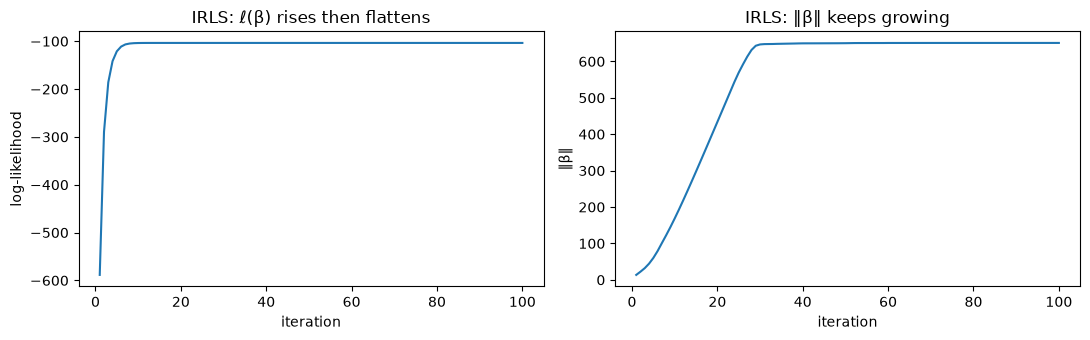

In [3]:
h = pd.DataFrame(r["history"])
print(f"IRLS converged: {r['conv_irls']} after {len(h)} iterations")
print(f"sklearn (C=inf, lbfgs) reports converged: {r['conv_sk']} after {r['sk_n_iter']} iterations")
print(f"log-likelihood  IRLS   : {r['ll_irls']:.6f}")
print(f"log-likelihood  sklearn: {r['ll_sk']:.6f}")
print(f"log-likelihood  null (intercept only): {r['ll_null']:.6f}")
display(h.iloc[[0, 1, 2, 4, 9, 19, 49, -1]][["iter", "objective", "gain", "beta_norm", "cond_H"]])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h.iter, h.objective); ax[0].set(xlabel="iteration", ylabel="log-likelihood", title="IRLS: ℓ(β) rises then flattens")
ax[1].plot(h.iter, h.beta_norm); ax[1].set(xlabel="iteration", ylabel="‖β‖", title="IRLS: ‖β‖ keeps growing")
plt.tight_layout(); plt.show()

In [4]:
c = r["coef"]
c = c.reindex(c.beta_irls_unpenalised.abs().sort_values(ascending=False).index)
print("max |β_IRLS − β_sklearn| =", round(float((c.beta_irls_unpenalised - c.beta_sklearn_unpenalised).abs().max()), 2))
c[["feature", "beta_irls_unpenalised", "beta_sklearn_unpenalised"]].head(10).round(2)

max |β_IRLS − β_sklearn| = 2705.12


,feature,beta_irls_unpenalised,beta_sklearn_unpenalised
107,tok=drugs,140.25,2563.69
228,tok=medicals,123.80,2386.91
84,tok=com,119.79,347.80
281,tok=pharmacy,116.91,1689.90
106,tok=drug,115.39,2543.53
433,pin=600020,-112.30,-1685.29
257,tok=nilayam,-102.51,-360.10
227,tok=medical,99.80,1474.97
135,tok=foods,-92.31,-1251.23
229,tok=medplus,91.43,1868.46


**Reading this:** both optimisers reach the *same* log-likelihood (to 6 decimals) but with
coefficients that disagree by thousands, and IRLS's $\lVert\beta\rVert$ keeps growing while
the gain in $\ell$ shrinks to zero. scikit-learn's "converged" flag only means its gradient
fell below tolerance on a nearly flat ridge; it does **not** mean a finite maximiser was found.
$X$ has full rank, so $X^\top W X$ starts well-conditioned, but its condition number explodes
as $\beta$ diverges and the weights $p_i(1-p_i)$ of separated rows collapse to 0.

In [5]:
sep = pd.DataFrame(r["separated"])
print(f"{len(sep)} of {len(fb.names) - 1} features separate the classes on their own "
      f"({(sep.only_class == 1).sum()} occur only in pharmacies, {(sep.only_class == 0).sum()} only in non-pharmacies)")
print("joint separation LP:", r["lp_full"])
print("MLE exists:", r["mle_exists"])
sep.sort_values("n_rows", ascending=False).head(12)

276 of 441 features separate the classes on their own (12 occur only in pharmacies, 264 only in non-pharmacies)
joint separation LP: {'separated': True, 'lp_optimum': 6017.0}
MLE exists: False


,feature,n_rows,only_class
142,tok=market,153,0
198,tok=ration,113,0
147,tok=medicals,98,1
272,tok=xerox,91,0
236,tok=stall,82,0
76,tok=electronics,81,0
86,tok=fish,81,0
75,tok=electricals,78,0
45,tok=chicken,69,0
154,tok=mobiles,68,0


### Conclusion: **the MLE does not exist** for this design

Single features already separate the classes, and a **joint check** confirms it: the linear
programme $\max_b \sum_i s_i x_i^\top b$ subject to $s_i x_i^\top b \ge 0$ and
$-1 \le b_j \le 1$ (with $s_i = 2y_i - 1$) has a positive optimum, so a separating direction
exists. (An optimum of 0 would mean no separating direction; with full rank the MLE would
then exist.)

The data are quasi-completely separated, so $\sup_\beta \ell(\beta)$ is not attained and the
unpenalised coefficients are artefacts of where each optimiser stopped. They must not be
interpreted. Their test metrics are reported below only for comparison and are labelled
*not a valid MLE*.

## 8. Pure-MLE demonstration: a small model where the MLE exists

A second, separate model with at most 10 title-token indicators. Tokens are taken in order
of **training-set** document frequency; a token is skipped if adding it would make the
training design rank-deficient or separated (checked with the LP above). Test labels are
never used. The unpenalised MLE is then fitted twice: hand-written IRLS and scikit-learn
`LogisticRegression(penalty=None)`.

In [6]:
sm = r["small"]
print("tokens (train document frequency):", sm["train_doc_freq"])
print("skipped before reaching 10:", sm["skipped_before_10"])
print(f"rank {sm['rank_X_train']} of {sm['n_columns']} columns | single-feature separators: "
      f"{len(sm['single_feature_separators'])} | joint LP: {sm['separation_lp']}")
print(f"IRLS converged: {sm['irls_converged']} in {sm['irls_iterations']} iterations; "
      f"sklearn penalty=None: {sm['sklearn_n_iter']} iterations (warnings: {sm['sklearn_warnings']})")
print(f"max |beta_IRLS - beta_sklearn| = {sm['max_abs_coef_diff_irls_vs_sklearn']:.2e}")
print(f"log-likelihood IRLS {sm['loglik_irls']:.10f} | sklearn {sm['loglik_sklearn']:.10f} | "
      f"|diff| {sm['abs_loglik_diff']:.2e}")
print("MLE exists:", sm["mle_exists"])
pd.DataFrame({"beta_irls": sm["coefficients"], "beta_sklearn": sm["coefficients_sklearn"]}).round(6)

tokens (train document frequency): {'shop': 471, 'store': 319, 'and': 236, 'sri': 209, 'chennai': 172, 'stores': 159, 'pharmacy': 154, 's': 126, 'home': 92, 'centre': 88}
skipped before reaching 10: [{'token': 'market', 'train_df': 153, 'reason': 'separation'}, {'token': 'ration', 'train_df': 113, 'reason': 'separation'}, {'token': 'medicals', 'train_df': 98, 'reason': 'separation'}, {'token': 'xerox', 'train_df': 91, 'reason': 'separation'}]
rank 11 of 11 columns | single-feature separators: 0 | joint LP: {'separated': False, 'lp_optimum': -0.0}
IRLS converged: True in 8 iterations; sklearn penalty=None: 8 iterations (warnings: ['FutureWarning'])
max |beta_IRLS - beta_sklearn| = 1.78e-15
log-likelihood IRLS -857.2225647143 | sklearn -857.2225647143 | |diff| 0.00e+00
MLE exists: True


,beta_irls,beta_sklearn
intercept,-2.325501,-2.325501
tok=shop,-1.641256,-1.641256
tok=store,-0.611848,-0.611848
tok=and,-0.460826,-0.460826
tok=sri,0.145233,0.145233
tok=chennai,-0.809174,-0.809174
tok=stores,-1.304321,-1.304321
tok=pharmacy,6.345290,6.345290
tok=s,-0.595575,-0.595575
tok=home,-1.784444,-1.784444


Here the MLE exists and is unique: no separating direction, full rank, Newton converges
quadratically in a handful of iterations, and two independent implementations agree to
machine precision. The `penalty=None` FutureWarning is scikit-learn 1.9.1 announcing the
argument's removal in 1.10; the pinned version still supports it.

## 9. Separate result: L2 model — penalised likelihood (MAP), not MLE

We add a penalty and maximise

$$\ell_\lambda(\beta) = \ell(\beta) - \frac{\lambda}{2}\sum_{j \ge 1}\beta_j^2
\qquad(\text{intercept not penalised}).$$

The penalty makes the objective strictly concave, so a unique finite maximiser always exists
(this is MAP estimation with a Gaussian prior $\beta_j \sim N(0, 1/\lambda)$: **penalised
likelihood (MAP), not MLE**).
scikit-learn parameterises it as $C = 1/\lambda$. $C$ is chosen by 5-fold stratified
cross-validation **on the training split only**, minimising log-loss.

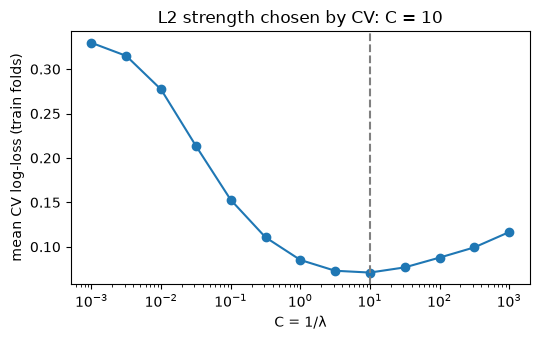

hand-written penalised IRLS converged: True
max |β_IRLS,L2 − β_sklearn,L2| = 1.37e-05
train log-likelihood of L2 model: -146.0539


,feature,beta_sklearn_l2,beta_irls_l2
228,tok=medicals,8.722,8.722
281,tok=pharmacy,8.512,8.512
227,tok=medical,8.028,8.028
229,tok=medplus,6.710,6.710
106,tok=drug,5.941,5.941
107,tok=drugs,5.604,5.604
173,tok=hospital,4.654,4.654
215,tok=makkal,4.094,4.094
0,intercept,-4.091,-4.091
359,tok=srm,3.864,3.864


In [7]:
cv = pd.Series(r["cv_curve"])
plt.figure(figsize=(5.5, 3.5)); plt.semilogx(cv.index, cv.values, marker="o")
plt.axvline(r["best_c"], ls="--", c="grey"); plt.xlabel("C = 1/λ"); plt.ylabel("mean CV log-loss (train folds)")
plt.title(f"L2 strength chosen by CV: C = {r['best_c']:g}"); plt.tight_layout(); plt.show()
c2 = r["coef"]
print(f"hand-written penalised IRLS converged: {r['conv_l2_irls']}")
print("max |β_IRLS,L2 − β_sklearn,L2| =", f"{(c2.beta_irls_l2 - c2.beta_sklearn_l2).abs().max():.2e}")
print(f"train log-likelihood of L2 model: {r['ll_l2']:.4f}")
c2.reindex(c2.beta_sklearn_l2.abs().sort_values(ascending=False).index)[["feature", "beta_sklearn_l2", "beta_irls_l2"]].head(12).round(3)

With the penalty, the hand-written Newton/IRLS solver and scikit-learn agree to ~1e-5:
the problem is now well-posed. The largest positive weights are pharmacy words
(*medical(s)*, *pharmacy*, *drug(s)*), which is what we would expect.

## 10. Held-out evaluation (test split, threshold 0.5)

In [8]:
rows = {"small-model MLE (MLE exists)": L.evaluate(r["y_te"], r["small"]["p_test"]),
        "L2 model: penalised likelihood (MAP), not MLE": L.evaluate(r["y_te"], r["p_l2"]),
        "unpenalised (NOT a valid MLE)": L.evaluate(r["y_te"], r["p_unpen"])}
base = L.majority_baseline(r["y_tr"], r["y_te"])
tab = pd.DataFrame({k: {m: v for m, v in d.items() if m != "confusion_matrix"} for k, d in rows.items()}).T
tab.loc["majority baseline (always 0)"] = [base["accuracy"], base["precision"], base["recall"], base["f1"],
                                           base["roc_auc"], base["pr_auc_equals_prevalence"], np.nan]
display(tab.round(4))
for k, d in rows.items():
    cm = d["confusion_matrix"]
    print(f"{k}: confusion matrix [[TN={cm['tn']}, FP={cm['fp']}], [FN={cm['fn']}, TP={cm['tp']}]]")
print(f"class balance test: {r['y_te'].sum()} positive / {len(r['y_te']) - r['y_te'].sum()} negative")

,accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss
small-model MLE (MLE exists),0.9328,1.0000,0.3608,0.5303,0.7438,0.4695,0.2428
"L2 model: penalised likelihood (MAP), not MLE",0.9870,0.9885,0.8866,0.9348,0.9842,0.9465,0.0583
unpenalised (NOT a valid MLE),0.9762,0.8947,0.8763,0.8854,0.9762,0.9094,0.3483
majority baseline (always 0),0.8949,0.0000,0.0000,0.0000,0.5000,0.1051,NaN


small-model MLE (MLE exists): confusion matrix [[TN=826, FP=0], [FN=62, TP=35]]
L2 model: penalised likelihood (MAP), not MLE: confusion matrix [[TN=825, FP=1], [FN=11, TP=86]]
unpenalised (NOT a valid MLE): confusion matrix [[TN=816, FP=10], [FN=12, TP=85]]
class balance test: 97 positive / 826 negative


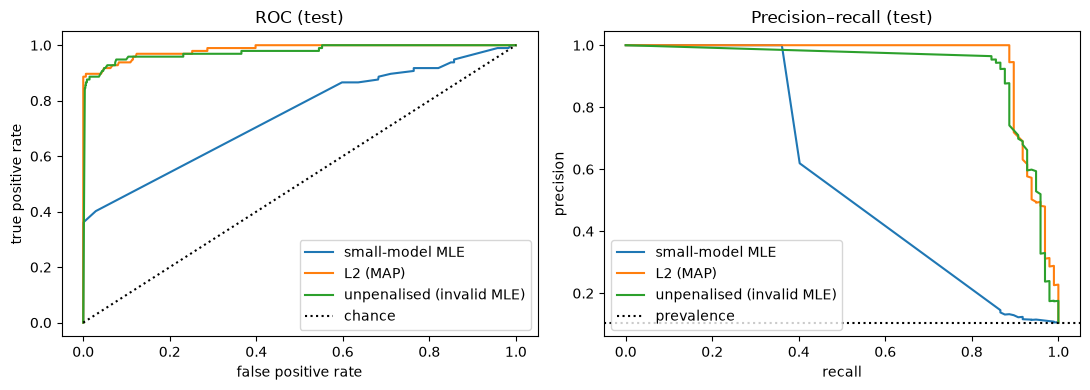

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, p in [("small-model MLE", r["small"]["p_test"]), ("L2 (MAP)", r["p_l2"]),
                ("unpenalised (invalid MLE)", r["p_unpen"])]:
    fpr, tpr, _ = roc_curve(r["y_te"], p); ax[0].plot(fpr, tpr, label=name)
    pr, rc, _ = precision_recall_curve(r["y_te"], p); ax[1].plot(rc, pr, label=name)
ax[0].plot([0, 1], [0, 1], "k:", label="chance"); ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC (test)")
ax[1].axhline(r["y_te"].mean(), c="k", ls=":", label="prevalence"); ax[1].set(xlabel="recall", ylabel="precision", title="Precision–recall (test)")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

## 11. Error analysis (L2 model): model mistakes or label noise?

In [10]:
t = r["test"].assign(p_l2=r["p_l2"])
err = t[(t.p_l2 >= 0.5) != (t.y == 1)]
err[["title", "categories", "y", "p_l2"]].round(3)

,title,categories,y,p_l2
2,The Buffet Square By SRM Hotels - Channai,bakery_sweets,0,0.568
42,More Supermarket,dairy_eggs;grocery_supermarket;kirana_provisio...,1,0.005
50,Sivagantha Illam,pharmacy,1,0.069
115,ANBU CHEMISTRY ACADEMY,pharmacy,1,0.031
169,Sumathi Stores,bakery_sweets;dairy_eggs;grocery_supermarket;h...,1,0.037
257,guru vallalar SIitha,pharmacy,1,0.045
380,Big Save Supermarket,dairy_eggs;grocery_supermarket;household_homew...,1,0.009
388,Vicky,pharmacy,1,0.031
484,MRS Surgicals,pharmacy,1,0.029
511,AUROPET CLINIC & PETSTORE,pet_supplies;pharmacy,1,0.349


Several "false negatives" look like **label noise**, not model errors: a chemistry academy,
supermarkets listed in 5–8 categories, and names with no pharmacy cue (*Vicky*). Others are
genuine misses (*PRABAL PHARMA*, *NEW PHARMA WORLD*). Test metrics against weak labels
therefore mix model error with label error.

To measure that noise, `data/annotation/label_audit_sample.csv` holds 200 test vendors
(all 97 weak positives + 103 weak negatives, shuffled) with a blank `true_is_pharmacy` column.
The sheet is blind: it does not show the weak label, categories or model score (those are in
`data/processed/label_audit_key.csv`). Because positives are oversampled, any noise estimate
from it must be re-weighted to the test prevalence.

## 12. Summary

* With the full feature set the unpenalised logistic-regression **MLE does not exist**: $X$
  has full column rank, but the training data are quasi-separated (hundreds of single-token
  separators, confirmed by the joint LP check).
* A small 10-token model chosen by training-set frequency is not separated, so its MLE
  exists; IRLS and scikit-learn `penalty=None` agree to machine precision. It is a valid MLE
  but a weak classifier.
* The L2 model is **penalised likelihood (MAP), not MLE**. It is well-posed, hand-written
  penalised IRLS reproduces scikit-learn, and it clearly beats the majority-class baseline.
* All test scores measure agreement with **weak, noisy** labels and should be read with that
  caveat.